In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sys
import os

# Get the current working directory
cwd = os.getcwd()

# Get the path to the project's root directory
root_path = os.path.abspath(os.path.join(cwd, os.pardir))

# Add the project's root directory to the Python module search path
sys.path.append(root_path)

In [2]:
from implementation.taylor_series import taylor_series


def f(x):
    return np.sin(x)


# Derivatives of sin(x) cycle: sin, cos, -sin, -cos, ...
sin_derivatives = [np.sin, np.cos, lambda x: -np.sin(x), lambda x: -np.cos(x)]


def derivatives(k):
    """Return derivative values of sin(x) at a=0 for array of orders k."""
    result = np.zeros_like(k, dtype=float)
    for i, order in enumerate(k):
        result[i] = sin_derivatives[int(order) % 4](0.0)
    return result


a = 0
x_test = np.pi / 4

for n in [3, 5, 7, 11]:
    approx = taylor_series(f, a, n, x_test, derivatives)
    print(f"n={n:2d}: Taylor approx = {approx:.10f}, exact = {np.sin(x_test):.10f}")

n= 3: Taylor approx = 0.7853981634, exact = 0.7071067812
n= 5: Taylor approx = 0.7046526512, exact = 0.7071067812
n= 7: Taylor approx = 0.7071430458, exact = 0.7071067812
n=11: Taylor approx = 0.7071067829, exact = 0.7071067812


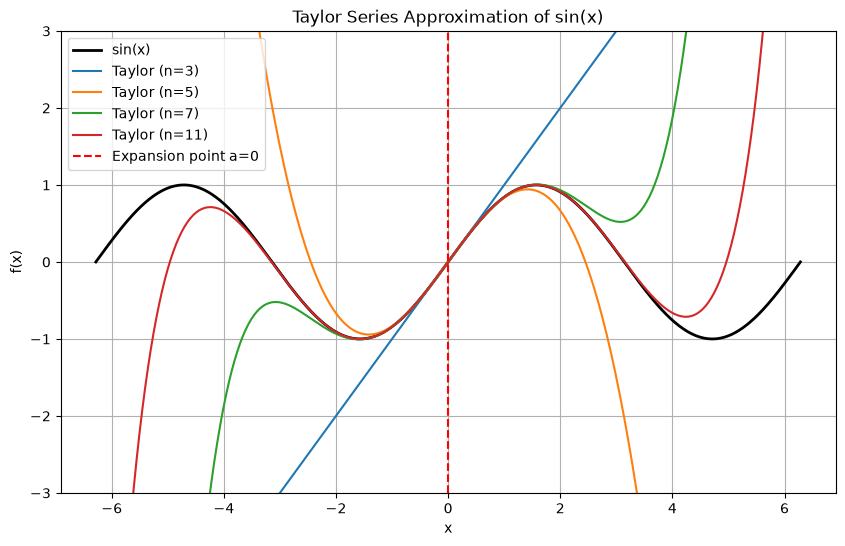

In [3]:
x_range = np.linspace(-2 * np.pi, 2 * np.pi, 500)

plt.figure(figsize=(10, 6))
plt.plot(x_range, np.sin(x_range), "k", linewidth=2, label="sin(x)")

for n in [3, 5, 7, 11]:
    y_approx = np.array([taylor_series(f, a, n, xi, derivatives) for xi in x_range])
    plt.plot(x_range, y_approx, label=f"Taylor (n={n})")

plt.ylim(-3, 3)
plt.axvline(x=a, color="red", linestyle="--", label=f"Expansion point a={a}")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Taylor Series Approximation of sin(x)")
plt.legend()
plt.grid(True)
plt.show()